# Kagome three-band model: bands, Berry curvature, Chern numbers and curvature spread

Three parts, each in its own cells:

1. **Band structure** for a chosen $(t,\lambda)$ and spin
2. **Berry curvature heatmap** (and Chern numbers) for a chosen $(t,\lambda)$ and spin
3. **Phase diagram** of the Berry curvature spread $\langle(\Delta F^n)^2\rangle$ versus $t$ and $\lambda$

Run the two setup cells first. After that, each part has its own parameter cell, so you can change $t$, $\lambda$ and the spin and re-run only that part.

---

## Read this first: everything the code assumes

### One Hamiltonian
All calculations use the same $3\times3$ matrix, built only from $k_n=\mathbf k\cdot\mathbf a_n$:

$$
h_\sigma(\mathbf k)=\begin{pmatrix}0&a&b\\ a^*&0&c\\ b^*&c^*&0\end{pmatrix},
$$

$$
a=-t\cos k_1+\sigma\,i\lambda\cos(k_2+k_3),\quad
b=-t\cos k_2-\sigma\,i\lambda\cos(k_3-k_1),\quad
c=-t\cos k_3+\sigma\,i\lambda\cos(k_1+k_2).
$$

- Your determinant is $\det\!\big(h_\sigma-\tfrac{E}{2}\mathbb 1\big)=0$. If $\varepsilon_n$ are the eigenvalues of $h_\sigma$, the band energies are $E_n=2\varepsilon_n$. **The band plot shows $E_n$.**
- **The spin.** The upper sign of the $\pm$ is spin up ($\sigma=+1$) and the lower sign is spin down ($\sigma=-1$). In the code this is the argument `spin`.
- **What the spin does.** The matrix of spin down is the complex conjugate of the matrix of spin up. Hence both spins have the **same energies**, and the Berry curvature and Chern number of each band **flip sign** between the two spins. The curvature spread is the same for both. Changing $\lambda\to-\lambda$ has the same effect as flipping the spin. For each band, the total Chern number over both spins is zero, and the spin Chern number is $C_s=(C_\uparrow-C_\downarrow)/2=C_\uparrow$.

### Lattice and Brillouin zone
- The lattice is kagome (three sites per unit cell, labelled 1, 2, 3). The nearest-neighbour vectors are $\mathbf a_1=\hat x$, $\mathbf a_2=(\hat x+\sqrt3\hat y)/2$ and $\mathbf a_3=\mathbf a_2-\mathbf a_1$, each of length 1, and $k_n=\mathbf k\cdot\mathbf a_n$.
- The **primitive lattice vectors** are $2\mathbf a_1=(2,0)$ and $2\mathbf a_2=(1,\sqrt3)$.
- The reciprocal vectors satisfy $\mathbf b_i\cdot(2\mathbf a_j)=2\pi\delta_{ij}$: $\mathbf b_1=(\pi,-\pi/\sqrt3)$ and $\mathbf b_2=(0,2\pi/\sqrt3)$. The Brillouin zone (BZ) has area $2\pi^2/\sqrt3$. It is drawn as the usual hexagon, with $\Gamma=(0,0)$, $M=\mathbf b_2/2$ and $K=(\mathbf b_1+2\mathbf b_2)/3$. The code integrates over the parallelogram spanned by $\mathbf b_1,\mathbf b_2$, which holds the same information.
- **Periodicity.** Because $h_\sigma$ is written with the true site positions, moving by a reciprocal vector flips the signs of some entries: $h\to U\,h\,U$ with $U=\mathrm{diag}(1,-1,1)$ or $\mathrm{diag}(1,1,-1)$. This does not change the energies, the Berry curvature or the Chern numbers.

### Band ordering
Bands are sorted by energy: $n=0$ is the **lowest** band and $n=2$ the **highest**.

### Berry curvature and Chern number
- Berry connection $A_\mu=-i\langle\psi_n|\partial_{k_\mu}\psi_n\rangle$, Berry curvature $F^n_{xy}=\partial_{k_x}A_y-\partial_{k_y}A_x$, and Chern number $C^n=\frac1{2\pi}\int_{\rm BZ}F^n_{xy}\,d^2k$ (an integer; the three bands sum to zero).
- **How it is computed.** The code uses the lattice method of Fukui and Hatsugai: it splits the BZ into $N\times N$ small cells and, for each cell, measures the phase that the eigenvector picks up going once around it. That phase equals the curvature times the area of the cell. No gauge fixing and no derivatives are needed.
- The heatmap shows $F^n_{xy}$ per unit area in the physical $(k_x,k_y)$ plane.

### The curvature spread
$$
\langle(\Delta F^n)^2\rangle=\frac1{4\pi^2}\int_{\rm BZ}\Big(F^n-\frac{C^n}{2\pi}\Big)^2d^2k .
$$

- The subtracted number $C^n/2\pi$ is the average curvature only when the zone has area $(2\pi)^2$. So the spread is evaluated with **dimensionless momenta** $q_1=\mathbf k\cdot2\mathbf a_1$, $q_2=\mathbf k\cdot2\mathbf a_2$ (the zone is then the square $[0,2\pi)^2$) and $F=F_{q_1q_2}=F_{xy}/(2\sqrt3)$. This makes the number independent of the length unit.
- If you prefer physical $(k_x,k_y)$ units, multiply the spread by the unit-cell area $2\sqrt3\approx3.46$ (the average to subtract is then $2\pi C^n/A_{\rm BZ}$).
- A small spread means the curvature is spread evenly over the zone; a large one means it is concentrated in a few places.

### What the results depend on
- The Chern numbers and the spread depend only on $\lambda/t$. The band energies scale with the size of $(t,\lambda)$.
- Symmetries used in Part 3: $t\to-t$ swaps the lowest and highest bands and flips all $C^n$; $\lambda\to-\lambda$ flips all $C^n$ (same as a spin flip); both leave the spread unchanged apart from the band swap.
- The gaps close at $|\lambda|/|t|=\sqrt3/2,\ 1,\ \sqrt3$ (found numerically) and at $\lambda=0$. There the Chern numbers jump and the spread becomes very large. Chern numbers for spin up, $t>0$, $\lambda>0$ (spin down has the opposite signs):

| $\lambda/t$ | $C^0$ | $C^1$ | $C^2$ |
|---|---|---|---|
| $0<\lambda/t<\sqrt3/2$ | $-1$ | $2$ | $-1$ |
| $\sqrt3/2<\lambda/t<1$ | $-1$ | $4$ | $-3$ |
| $1<\lambda/t<\sqrt3$ | $-1$ | $-2$ | $3$ |
| $\lambda/t>\sqrt3$ | $-3$ | $0$ | $3$ |

### Practical notes
- The code prints a warning when a computed Chern number is not close to an integer. Near a gap closing, increase `N`.
- Required packages: `numpy` and `matplotlib` only.

## Setup (run first)

**Cell 1: imports and plot settings.**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.colors import LogNorm

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})
SQ3 = np.sqrt(3.0)
SPIN_NAME = {+1: "spin up", -1: "spin down"}

**Cell 2: lattice and the Hamiltonian.**

`hamiltonian(kx, ky, t, lam, spin)` is the only definition of the Hamiltonian in this notebook. It works on arrays of any shape and returns matrices of shape `(..., 3, 3)`. The helper `bz_grid` places an $(N+1)\times(N+1)$ grid of points on the parallelogram spanned by $\mathbf b_1,\mathbf b_2$.

In [2]:
# nearest-neighbour vectors (length 1) and primitive vectors (twice as long)
a1 = np.array([1.0, 0.0])
a2 = np.array([0.5, SQ3/2])
a3 = a2 - a1
R1, R2 = 2*a1, 2*a2                                   # primitive lattice vectors
RMAT = np.array([R1, R2])
BVEC = 2*np.pi*np.linalg.inv(RMAT).T                  # rows are b1, b2  (b_i . R_j = 2 pi delta_ij)
B1, B2 = BVEC
CELL_AREA = abs(np.linalg.det(RMAT))                  # real-space unit-cell area = 2 sqrt(3)
BZ_AREA = abs(np.linalg.det(BVEC))                    # = (2 pi)^2 / CELL_AREA
K_POINT = (B1 + 2*B2)/3                               # corner of the hexagonal zone

def hamiltonian(kx, ky, t, lam, spin=+1):
    """The 3x3 Bloch matrix h_sigma(k) with k_n = k . a_n.
    spin = +1 : upper sign (spin up);  spin = -1 : lower sign (spin down)."""
    kx, ky = np.broadcast_arrays(np.asarray(kx, float), np.asarray(ky, float))
    k1 = kx*a1[0] + ky*a1[1]
    k2 = kx*a2[0] + ky*a2[1]
    k3 = kx*a3[0] + ky*a3[1]
    a = -t*np.cos(k1) + spin*1j*lam*np.cos(k2 + k3)
    b = -t*np.cos(k2) - spin*1j*lam*np.cos(k3 - k1)
    c = -t*np.cos(k3) + spin*1j*lam*np.cos(k1 + k2)
    h = np.zeros(kx.shape + (3, 3), dtype=complex)
    h[..., 0, 1], h[..., 0, 2], h[..., 1, 2] = a, b, c
    h[..., 1, 0], h[..., 2, 0], h[..., 2, 1] = a.conj(), b.conj(), c.conj()
    return h

def bz_grid(N):
    """(N+1)x(N+1) points on the cell spanned by b1, b2 (corners included)."""
    u = np.linspace(0.0, 1.0, N + 1)
    U1, U2 = np.meshgrid(u, u, indexing="ij")
    return U1*B1[0] + U2*B2[0], U1*B1[1] + U2*B2[1]

print("primitive vectors:", R1, R2)
print("b1 =", np.round(B1, 4), "  b2 =", np.round(B2, 4), "  BZ area =", round(BZ_AREA, 4),
      "(2 pi^2/sqrt(3) =", round(2*np.pi**2/SQ3, 4), ")")

primitive vectors: [2. 0.] [1.         1.73205081]
b1 = [ 3.1416 -1.8138]   b2 = [0.     3.6276]   BZ area = 11.3964 (2 pi^2/sqrt(3) = 11.3964 )


# Part 1: Band structure

The energies are $E_n=2\varepsilon_n$, where $\varepsilon_n$ are the eigenvalues of $h_\sigma$.

**Cell 3: functions.**

- `bands` gives the three energies at any $(k_x,k_y)$ by diagonalizing `hamiltonian`.
- `bands_closed_form` is an optional cross-check from the exact formula $E_n=4\sqrt{S/3}\cos\!\big[\tfrac13\arccos\!\big(3\sqrt3R/S^{3/2}\big)-\tfrac{2\pi n}{3}\big]$, valid for both spins.
- `k_path` builds straight lines through the high-symmetry points of the zone (default $\Gamma\to M\to K\to\Gamma$).

In [3]:
def bands(kx, ky, t, lam, spin=+1):
    """Energies E_n = 2*eps_n sorted ascending, shape (..., 3)."""
    return 2*np.linalg.eigvalsh(hamiltonian(kx, ky, t, lam, spin))

def bands_closed_form(kx, ky, t, lam):
    """Exact solution of E^3 - 4 S E - 16 R = 0 (same for both spins)."""
    kx, ky = np.asarray(kx, float), np.asarray(ky, float)
    k1 = kx*a1[0] + ky*a1[1]; k2 = kx*a2[0] + ky*a2[1]; k3 = kx*a3[0] + ky*a3[1]
    C1, C2, C3 = np.cos(k1), np.cos(k2), np.cos(k3)
    D1, D2, D3 = np.cos(k2 + k3), np.cos(k3 - k1), np.cos(k1 + k2)
    S = t**2*(C1**2 + C2**2 + C3**2) + lam**2*(D1**2 + D2**2 + D3**2)
    R = -t**3*C1*C2*C3 + t*lam**2*(C2*D1*D3 + C1*D2*D3 + C3*D1*D2)
    S = np.maximum(S, 1e-300)
    arg = np.clip(3*SQ3*R/S**1.5, -1, 1)
    E = np.stack([4*np.sqrt(S/3)*np.cos(np.arccos(arg)/3 - 2*np.pi*n/3) for n in range(3)], axis=-1)
    return np.sort(E, axis=-1)

HSP = {"Γ": np.array([0.0, 0.0]), "M": B2/2, "K": K_POINT}     # high-symmetry points (kx, ky)

def k_path(labels=("Γ", "M", "K", "Γ"), n_per_segment=150):
    pts = [HSP[l] for l in labels]
    kk, xx, ticks, x0 = [], [], [0.0], 0.0
    for p, q in zip(pts[:-1], pts[1:]):
        s = np.linspace(0, 1, n_per_segment, endpoint=False)
        kk.append(p + s[:, None]*(q - p))
        xx.append(x0 + s*np.linalg.norm(q - p))
        x0 += np.linalg.norm(q - p)
        ticks.append(x0)
    kk.append(pts[-1][None, :]); xx.append(np.array([x0]))
    return np.vstack(kk), np.concatenate(xx), np.array(ticks), list(labels)

**Cell 4: parameters for Part 1.** `spins_band` lists the spins to draw: `(+1,)` for spin up only, `(-1,)` for spin down only, or `(+1, -1)` for both.

**Cell 5: plot the bands.** Spin up is drawn as solid lines and spin down as dashed lines. The two sets lie on top of each other, which the printed difference confirms. The check against the closed form should give about $10^{-15}$. The text at the end gives the smallest direct gaps over the whole zone.

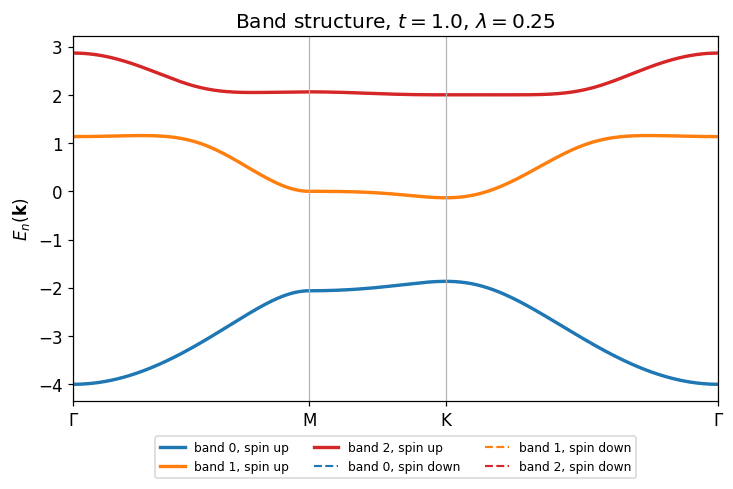

max |numerical - closed form|, per spin: {'spin up': 2.6645352591003757e-15, 'spin down': 2.6645352591003757e-15}
max |E(spin up) - E(spin down)|: 0.0
smallest gap between band 0 and 1: 1.73205
smallest gap between band 1 and 2: 1.1268


In [14]:
t_band     = 1.0
lam_band   = 0.25
spins_band = (+1, -1)

kpts, xdist, ticks, tlabels = k_path()
fig, ax = plt.subplots(figsize=(6.8, 4.6))
styles = {+1: dict(ls="-", lw=2.2), -1: dict(ls="--", lw=1.4)}
Eall = {}
for s in spins_band:
    Eall[s] = bands(kpts[:, 0], kpts[:, 1], t_band, lam_band, s)
    for n, col in enumerate(["C0", "C1", "C3"]):
        ax.plot(xdist, Eall[s][:, n], color=col, label=f"band {n}, {SPIN_NAME[s]}", **styles[s])
for x in ticks:
    ax.axvline(x, color="0.7", lw=0.8)
ax.set_xticks(ticks); ax.set_xticklabels(tlabels); ax.set_xlim(xdist[0], xdist[-1])
ax.set_ylabel(r"$E_n(\mathbf{k})$")
ax.set_title(rf"Band structure, $t={t_band}$, $\lambda={lam_band}$")
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08)); fig.tight_layout(); plt.show()

Ec = bands_closed_form(kpts[:, 0], kpts[:, 1], t_band, lam_band)
print("max |numerical - closed form|, per spin:", {SPIN_NAME[s]: float(np.abs(E - Ec).max()) for s, E in Eall.items()})
if len(Eall) == 2:
    print("max |E(spin up) - E(spin down)|:", float(np.abs(Eall[+1] - Eall[-1]).max()))

# smallest direct gaps over the whole zone (spin up; spin down is identical)
KX, KY = bz_grid(240)
Eg = bands(KX, KY, t_band, lam_band, +1)
print("smallest gap between band 0 and 1:", round((Eg[..., 1] - Eg[..., 0]).min(), 5))
print("smallest gap between band 1 and 2:", round((Eg[..., 2] - Eg[..., 1]).min(), 5))

# Part 2: Berry curvature heatmap and Chern numbers

**Cell 6: functions.**

- `berry_curvature_grid` splits the parallelogram into $N\times N$ small cells and returns, for each band, the curvature per unit area `F_k` in $(k_x,k_y)$, the dimensionless version `F_q` (used for the spread in Part 3), and the integer Chern numbers.
- `plot_berry_curvature` draws one row of heatmaps per requested spin. With `region="hexagon"` it repeats the zone to fill the usual hexagon around $\Gamma$ (allowed because the curvature is periodic); with `region="cell"` it draws the parallelogram. Colour ranges are symmetric about zero and set by the 99th percentile, so sharp peaks do not wash out the rest.

In [5]:
def berry_curvature_grid(t, lam, N=200, spin=+1, verbose=True, gap_tol=1e-8):
    """Fukui-Hatsugai Berry curvature of the three bands on an N x N grid covering the BZ."""
    KX, KY = bz_grid(N)
    w, v = np.linalg.eigh(hamiltonian(KX, KY, t, lam, spin))      # v[..., :, n] is band n

    # Check the direct gaps throughout the sampled BZ
    gap01 = 2*np.min(w[..., 1] - w[..., 0])
    gap12 = 2*np.min(w[..., 2] - w[..., 1])

    # Explicitly check high-symmetry points
    # (important when the grid does not contain K)
    KX_check = np.array([0.0, K_POINT[0]])
    KY_check = np.array([0.0, K_POINT[1]])

    w_check = np.linalg.eigvalsh(
        hamiltonian(KX_check, KY_check, t, lam, spin)
    )

    gap01 = min(
        gap01,
        2*np.min(w_check[..., 1] - w_check[..., 0])
    )
    gap12 = min(
        gap12,
        2*np.min(w_check[..., 2] - w_check[..., 1])
    )

    if min(gap01, gap12) < gap_tol:
        raise ValueError(
            f"Individual band Chern numbers are undefined: "
            f"gap01={gap01:.3e}, gap12={gap12:.3e}"
        )
    
    link = lambda x, y: np.sum(x.conj()*y, axis=-1)                # <x|y>
    flux = np.empty((3, N, N))
    for n in range(3):
        p = v[..., n]
        loop = (link(p[:-1, :-1], p[1:, :-1]) * link(p[1:, :-1], p[1:, 1:]) *
                link(p[1:, 1:], p[:-1, 1:])   * link(p[:-1, 1:], p[:-1, :-1]))
        flux[n] = np.angle(loop)                                   # = F * (area of the small cell)
    c_raw = flux.sum(axis=(1, 2))/(2*np.pi)
    chern = np.round(c_raw).astype(int)
    if verbose and np.abs(c_raw - chern).max() > 0.05:
        print("WARNING: Chern numbers are not close to integers", np.round(c_raw, 3),
              "-> increase N (a gap is probably very small).")
    dq = 2*np.pi/N                                                 # cell size in dimensionless momenta
    return dict(KX=KX, KY=KY, chern=chern, chern_raw=c_raw, flux=flux,
                F_k=flux/(BZ_AREA/N**2),                           # per unit area in (kx, ky)
                F_q=flux/dq**2,                                    # per unit area in (q1, q2), zone area (2 pi)^2
                gap01=2*(w[..., 1] - w[..., 0]).min(), gap12=2*(w[..., 2] - w[..., 1]).min())

def plot_berry_curvature(t, lam, N=200, spins=(+1, -1), region="hexagon", cmap="RdBu_r"):
    R = np.linalg.norm(K_POINT)                                    # distance from Gamma to a zone corner
    hexa = np.array([[R*np.cos(a), R*np.sin(a)] for a in np.deg2rad(np.arange(0, 360, 60))])
    tiles = [(m1, m2) for m1 in (-1, 0) for m2 in (-1, 0)] if region == "hexagon" else [(0, 0)]
    fig, axes = plt.subplots(len(spins), 3, figsize=(15, 4.6*len(spins)), squeeze=False)
    results = {}
    for r, s in enumerate(spins):
        res = berry_curvature_grid(t, lam, N, s); results[s] = res
        for n in range(3):
            ax = axes[r, n]
            F = res["F_k"][n]; vmax = np.percentile(np.abs(F), 99)
            patch = Polygon(hexa, closed=True, fill=False, ec="k", lw=1.2, transform=ax.transData)
            if region == "hexagon":
                ax.add_patch(patch)
            for (m1, m2) in tiles:
                off = m1*B1 + m2*B2
                mesh = ax.pcolormesh(res["KX"] + off[0], res["KY"] + off[1], F, cmap=cmap,
                                     vmin=-vmax, vmax=vmax, shading="flat", rasterized=True)
                if region == "hexagon":
                    mesh.set_clip_path(patch)
            if region == "cell":
                ax.add_patch(Polygon([[0, 0], B1, B1 + B2, B2], closed=True, fill=False, ec="k", lw=1.2))
                ax.set_xlim(min(0, B1[0], B2[0]) - .2, (B1 + B2)[0] + .2)
                ax.set_ylim(min(0, B1[1]) - .2, (B1 + B2)[1] + .2)
            else:
                ax.set_xlim(-1.15*R, 1.15*R); ax.set_ylim(-1.15*R, 1.15*R)
            ax.set_aspect("equal"); ax.set_xlabel(r"$k_x$"); ax.set_ylabel(r"$k_y$")
            ax.set_title(rf"{SPIN_NAME[s]}, band {n}:  $C={res['chern'][n]}$")
            fig.colorbar(mesh, ax=ax, shrink=0.8, label=r"$F^n_{xy}$")
    fig.suptitle(rf"Berry curvature, $t={t}$, $\lambda={lam}$", y=1.0)
    fig.tight_layout(); plt.show()
    return results

**Cell 7: parameters for Part 2.** `spins_bc` lists the spins to draw. The default $\lambda/t=0.3$ lies in the first phase, where spin up has $C=(-1,2,-1)$.

**Cell 8: run Part 2.** It prints the Chern numbers of each spin, the spin Chern number $C_s=(C_\uparrow-C_\downarrow)/2$ and the total Chern number, plus the smallest gaps.

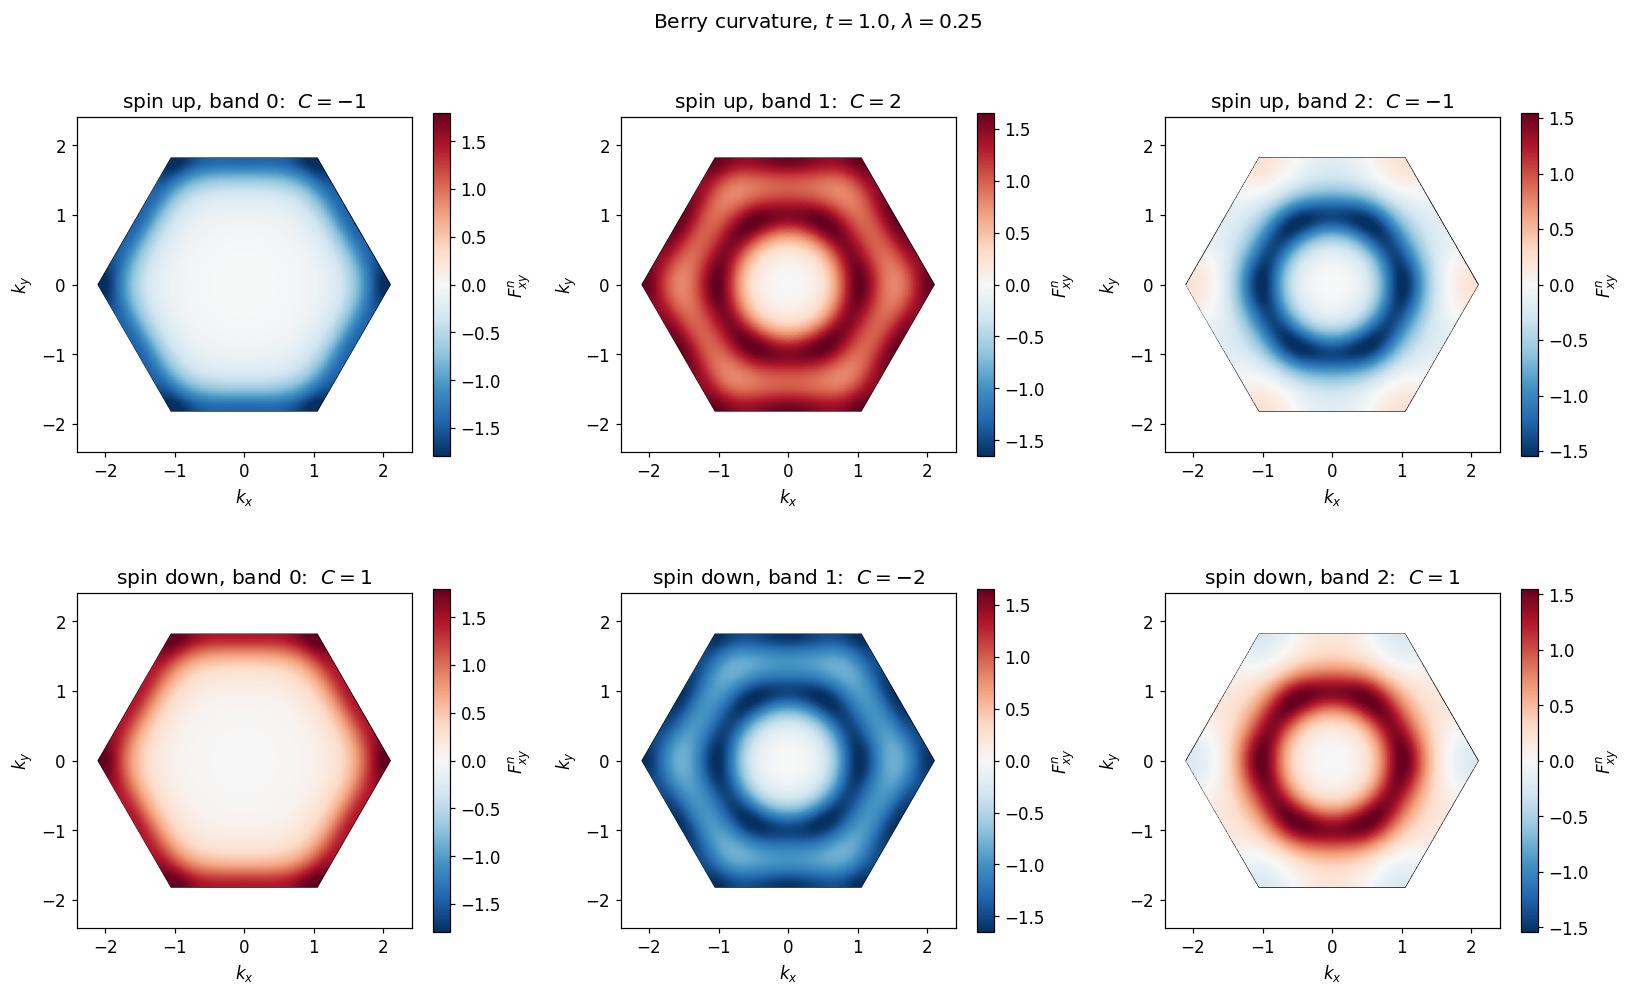

spin up   : Chern numbers (band 0, 1, 2) = [-1  2 -1],  sum = 0
spin down : Chern numbers (band 0, 1, 2) = [ 1 -2  1],  sum = 0
spin Chern numbers (C_up - C_down)/2: [-1  2 -1]    total Chern numbers (C_up + C_down): [0 0 0]
smallest direct gaps  E1-E0: 1.7321   E2-E1: 1.1268


In [13]:
t_bc      = 1.0
lam_bc    = 0.25
N_bc      = 300      # grid size: larger = smoother but slower (try 300-400 near a gap closing)
spins_bc  = (+1, -1)
region_bc = "hexagon"   # "hexagon" (usual first BZ) or "cell" (parallelogram spanned by b1, b2)

res_bc = plot_berry_curvature(t_bc, lam_bc, N_bc, spins_bc, region_bc)
for s, res in res_bc.items():
    print(f"{SPIN_NAME[s]:10s}: Chern numbers (band 0, 1, 2) = {res['chern']},  sum = {res['chern'].sum()}")
if +1 in res_bc and -1 in res_bc:
    print("spin Chern numbers (C_up - C_down)/2:", (res_bc[+1]['chern'] - res_bc[-1]['chern'])//2,
          "   total Chern numbers (C_up + C_down):", res_bc[+1]['chern'] + res_bc[-1]['chern'])
any_res = next(iter(res_bc.values()))
print("smallest direct gaps  E1-E0: %.4f   E2-E1: %.4f" % (any_res["gap01"], any_res["gap12"]))

# Part 3: Phase diagram of the curvature spread

Everything depends only on $\lambda/t$, so it is enough to scan the angle $\phi$ with $t=\cos\phi$, $\lambda=\sin\phi$, for $\phi\in(0,\pi/2)$ and spin up. The rest of the $(t,\lambda)$ plane, and spin down, follow from the symmetries listed at the top. Cell 10 checks them directly.

**Cell 9: functions.**

- `curvature_spread` returns the three Chern numbers and the three spreads for one $(t,\lambda)$ and spin, computed in the dimensionless momenta described at the top.
- `scan_spread` repeats this along $\phi$ (spin up). With `refine=True` it adds extra points near the three gap closings.
- `plot_phase_diagram` draws one map per band over the plane $(t,\lambda)$ (colour = spread, white dashed lines = phase boundaries, numbers = Chern number of that band for the chosen `spin`) and a line plot against $|\lambda|/|t|$.

In [7]:
CRIT_RATIOS = np.array([SQ3/2, 1.0, SQ3])       # gap-closing values of |lambda|/|t| (found numerically)
CRIT_PHI = np.arctan(CRIT_RATIOS)

def curvature_spread(t, lam, N=200, spin=+1):
    """Chern numbers and spread <(Delta F^n)^2> with the zone normalised to area (2 pi)^2."""
    res = berry_curvature_grid(t, lam, N, spin, verbose=False)
    dq = 2*np.pi/N
    C = res["chern"]
    var = ((res["F_q"] - C[:, None, None]/(2*np.pi))**2).sum(axis=(1, 2))*dq**2/(4*np.pi**2)
    return C, var

def scan_spread(n_phi=140, N=160, refine=True, spin=+1):
    phi = np.linspace(0.01, np.pi/2 - 0.01, n_phi)
    if refine:
        offs = np.array([-.06, -.03, -.015, -.007, -.003, .003, .007, .015, .03, .06])
        phi = np.unique(np.concatenate([phi] + [c + offs for c in CRIT_PHI]))
    Cs, Vs = np.zeros((len(phi), 3), int), np.zeros((len(phi), 3))
    for j, p in enumerate(phi):
        Cs[j], Vs[j] = curvature_spread(np.cos(p), np.sin(p), N, spin)
    return phi, Cs.T, Vs.T                      # shapes (n_phi,), (3, n_phi), (3, n_phi)

def plot_phase_diagram(phi, Cs, Vs, L=2.0, npix=600, vmin=1e-2, vmax=20.0, spin=+1):
    """phi, Cs, Vs come from scan_spread (spin up); spin=-1 only flips the Chern labels."""
    t = np.linspace(-L, L, npix); lam = np.linspace(-L, L, npix)
    T, LAM = np.meshgrid(t, lam)
    P = np.clip(np.arctan2(np.abs(LAM), np.abs(T)), phi[0], phi[-1])
    names = ["band 0 (lowest)", "band 1 (middle)", "band 2 (highest)"]

    def field(b):                               # t<0 : lowest and highest bands are swapped
        out = np.interp(P, phi, Vs[b])
        neg = T < 0
        out[neg] = np.interp(P[neg], phi, Vs[2 - b])
        return out

    def chern_label(b, p_mid, tsign, lsign):    # Chern number of band b in a wedge, for the chosen spin
        j = np.argmin(np.abs(phi - p_mid))
        c = lsign*Cs[b, j] if tsign > 0 else -lsign*Cs[2 - b, j]
        return int(spin*c)

    edges = np.concatenate([[0.0], CRIT_PHI, [np.pi/2]])
    fig = plt.figure(figsize=(16, 10.5))
    gs = fig.add_gridspec(2, 3, height_ratios=[1.15, 1], hspace=0.28, wspace=0.28)
    for b in range(3):
        ax = fig.add_subplot(gs[0, b])
        im = ax.pcolormesh(T, LAM, field(b), cmap="viridis", norm=LogNorm(vmin=vmin, vmax=vmax),
                           shading="auto", rasterized=True)
        for c in CRIT_PHI:                      # phase boundaries
            for st in (1, -1):
                for sl in (1, -1):
                    x, y = st*L, sl*L*np.tan(c)
                    if abs(y) > L:
                        x, y = st*L/np.tan(c), sl*L
                    ax.plot([0, x], [0, y], "w--", lw=0.9)
        for k in range(4):                      # Chern labels, all four quadrants
            pm = 0.5*(edges[k] + edges[k + 1])
            for st in (1, -1):
                for sl in (1, -1):
                    ax.text(st*1.55*np.cos(pm), sl*1.55*np.sin(pm), f"{chern_label(b, pm, st, sl):+d}",
                            color="w", ha="center", va="center", fontsize=10, fontweight="bold",
                            bbox=dict(boxstyle="round,pad=0.15", fc="k", alpha=0.45, lw=0))
        ax.set_title(names[b]); ax.set_xlabel(r"$t$"); ax.set_ylabel(r"$\lambda$"); ax.set_aspect("equal")
    cax = fig.add_axes([0.92, 0.56, 0.012, 0.31])
    fig.colorbar(im, cax=cax).set_label(rf"$\langle(\Delta F^n)^2\rangle$  (log scale, clipped to {vmin:g} to {vmax:g})")

    ax = fig.add_subplot(gs[1, :])
    for b, col in enumerate(["C0", "C1", "C3"]):
        ax.plot(np.tan(phi), Vs[b], color=col, lw=1.6, label=names[b])
    for r, lab, ha, dx in zip(CRIT_RATIOS, [r"$\sqrt{3}/2$", r"$1$", r"$\sqrt{3}$"],
                              ["right", "left", "left"], [0.99, 1.01, 1.01]):
        ax.axvline(r, color="k", ls="--", lw=0.9)
        ax.text(r*dx, vmax*1.5, lab, fontsize=11, va="bottom", ha=ha)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-4, vmax*1.5)
    ax.set_xlabel(r"$|\lambda|/|t|$  (for $t>0$)"); ax.set_ylabel(r"$\langle(\Delta F^n)^2\rangle$")
    ax.grid(alpha=0.3, which="both"); ax.legend(loc="upper left")
    fig.suptitle(rf"Curvature spread vs $t$ and $\lambda$  (numbers on the maps: Chern number of that band, {SPIN_NAME[spin]})",
                 fontsize=14, y=0.96)
    plt.show()

**Cell 10: check of the spin symmetry and of the Chern numbers.** For one value of $\lambda/t$ in each phase ($t=1$) it prints the Chern numbers and spreads of both spins. Expected: $C_\downarrow=-C_\uparrow$ and identical spreads. It takes a few seconds.

In [8]:
expected_up = {0.3: (-1, 2, -1), 0.95: (-1, 4, -3), 1.5: (-1, -2, 3), 3.0: (-3, 0, 3)}
for r, exp in expected_up.items():
    Cu, Vu = curvature_spread(1.0, r, N=200, spin=+1)
    Cd, Vd = curvature_spread(1.0, r, N=200, spin=-1)
    print(f"lambda/t = {r:4}:  C_up = {tuple(int(c) for c in Cu)} (expected {exp}),  "
          f"C_down = {tuple(int(c) for c in Cd)},  spread up = {np.round(Vu, 4)},  max|spread up - down| = {np.abs(Vu - Vd).max():.1e}")

lambda/t =  0.3:  C_up = (-1, 2, -1) (expected (-1, 2, -1)),  C_down = (1, -2, 1),  spread up = [0.0205 0.016  0.0219],  max|spread up - down| = 0.0e+00
lambda/t = 0.95:  C_up = (-1, 4, -3) (expected (-1, 4, -3)),  C_down = (1, -4, 3),  spread up = [ 0.041  11.1079 11.1601],  max|spread up - down| = 0.0e+00
lambda/t =  1.5:  C_up = (-1, -2, 3) (expected (-1, -2, 3)),  C_down = (1, 2, -3),  spread up = [0.0679 0.4393 0.3897],  max|spread up - down| = 0.0e+00
lambda/t =  3.0:  C_up = (-3, 0, 3) (expected (-3, 0, 3)),  C_down = (3, 0, -3),  spread up = [0.1397 0.2922 0.1341],  max|spread up - down| = 0.0e+00


**Cell 11: scan settings for Part 3.**

- `n_phi` is the number of values of $\phi$ in the regular part of the scan.
- `N` is the grid size per point. Larger `N` is more accurate near the phase boundaries but slower.
- The defaults take about 20 seconds. For a publication-quality figure try `n_phi=260`, `N=320`.
- `spin_labels` chooses whether the Chern numbers written on the maps are those of spin up (`+1`) or spin down (`-1`).

In [9]:
n_phi_scan  = 260
N_scan      = 320
spin_labels = +1

**Cell 12: run the scan** (this is the slow cell).

In [10]:
phi_s, C_s, V_s = scan_spread(n_phi_scan, N_scan, refine=True, spin=+1)
print("scanned", len(phi_s), "values of phi")

scanned 290 values of phi


**Cell 13: draw the phase diagram.** The window `L` sets the range $-L<t,\lambda<L$.

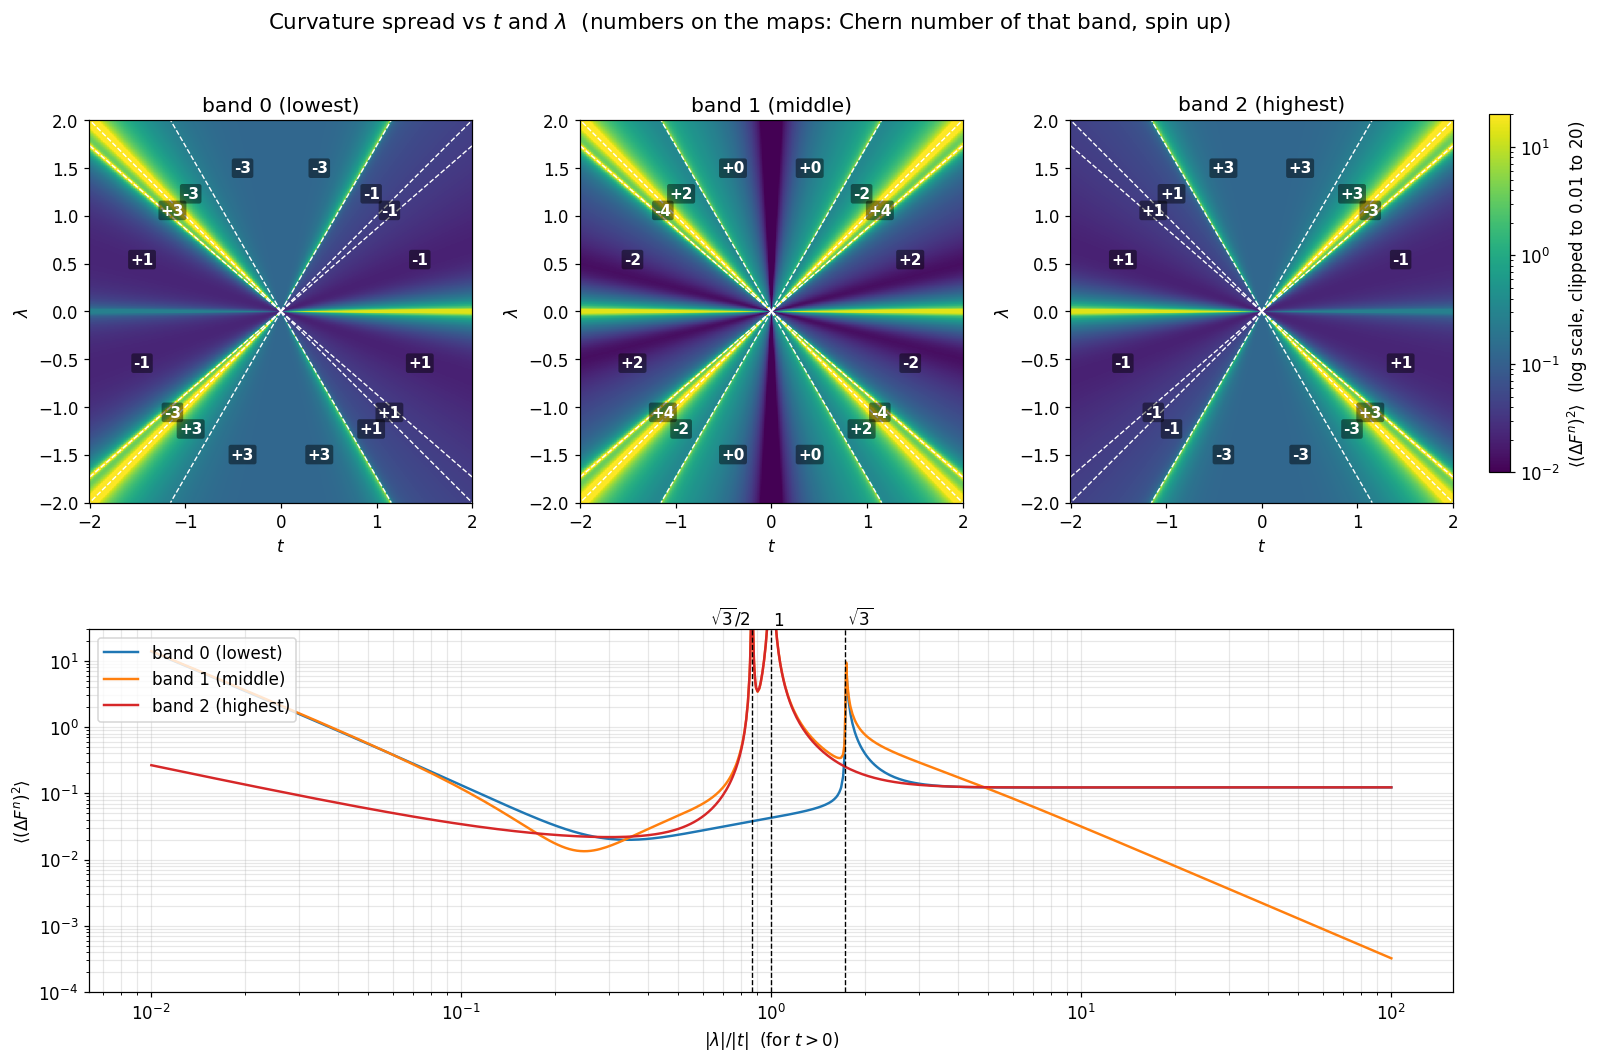

In [11]:
plot_phase_diagram(phi_s, C_s, V_s, L=2.0, spin=spin_labels)

## Zoom into the physically relevant window $0<\lambda/t\le1$

Since $\lambda$ is a next-nearest-neighbour hopping, one expects $\lambda<t$ in a real system. **Cell 14** shows only that window, using the scan from Cell 12:

- **Left:** the curvature spread of each band versus $\lambda/t$.
- **Right:** the smallest direct gaps $\min_{\mathbf k}(E_1-E_0)$ and $\min_{\mathbf k}(E_2-E_1)$ in units of $t$. A small gap means the curvature piles up near one point of the zone. The gaps are the same for both spins.

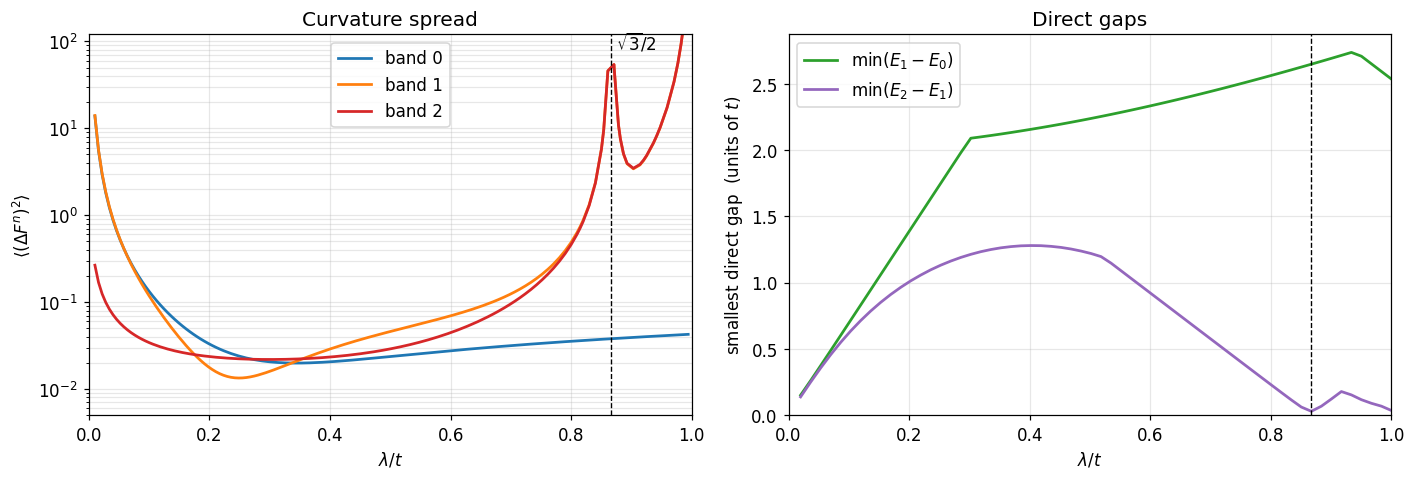

In [12]:
def min_gaps(t, lam, N=121, spin=+1):
    KX, KY = bz_grid(N)
    E = bands(KX, KY, t, lam, spin)
    return (E[..., 1] - E[..., 0]).min(), (E[..., 2] - E[..., 1]).min()

def plot_window(phi, Vs, rmax=1.0):
    r = np.tan(phi); m = r <= rmax
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
    for b, col in enumerate(["C0", "C1", "C3"]):
        ax1.plot(r[m], Vs[b][m], color=col, lw=1.8, label=f"band {b}")
    ax1.axvline(SQ3/2, color="k", ls="--", lw=0.9)
    ax1.text(SQ3/2, 80, r" $\sqrt{3}/2$", fontsize=11)
    ax1.set_yscale("log"); ax1.set_ylim(5e-3, 1.2e2); ax1.set_xlim(0, rmax)
    ax1.set_xlabel(r"$\lambda/t$"); ax1.set_ylabel(r"$\langle(\Delta F^n)^2\rangle$")
    ax1.grid(alpha=0.3, which="both"); ax1.legend(loc="upper center"); ax1.set_title("Curvature spread")
    rr = np.linspace(0.02, rmax, 60)
    g = np.array([min_gaps(1.0, x) for x in rr])
    ax2.plot(rr, g[:, 0], color="C2", lw=1.8, label=r"$\min(E_1-E_0)$")
    ax2.plot(rr, g[:, 1], color="C4", lw=1.8, label=r"$\min(E_2-E_1)$")
    ax2.axvline(SQ3/2, color="k", ls="--", lw=0.9)
    ax2.set_xlim(0, rmax); ax2.set_ylim(0, None)
    ax2.set_xlabel(r"$\lambda/t$"); ax2.set_ylabel(r"smallest direct gap  (units of $t$)")
    ax2.grid(alpha=0.3); ax2.legend(); ax2.set_title("Direct gaps")
    fig.tight_layout(); plt.show()

plot_window(phi_s, V_s, rmax=1.0)

In [23]:
print(curvature_spread(1.0, 0.25, N=200, spin=+1))

(array([-1,  2, -1]), array([0.02384063, 0.01338056, 0.02224914]))


## Reading the result

- The $(t,\lambda)$ plane is divided into wedges by the lines $|\lambda|=\tfrac{\sqrt3}{2}|t|$, $|t|$ and $\sqrt3|t|$. The Chern numbers are constant inside each wedge. Spin down has the opposite Chern numbers, so the total Chern number of each band is zero and the spin Chern number is $C_\uparrow$.
- The spread becomes very large along each boundary and along $\lambda=0$, where a gap closes.
- Away from the boundaries the spread is smallest (about $0.013$ to $0.022$) near $\lambda/t\approx0.2$ to $0.4$. For $|\lambda|/|t|\to\infty$ the outer bands approach about $0.123$ and the middle band approaches zero. In physical $(k_x,k_y)$ units multiply all spreads by $2\sqrt3$.
- The energies are identical for both spins; only the sign of the Berry curvature differs.